# Pocket Clock ⏱️
### Combien de temps la poche protège-t-elle le quarterback ?
*Et comment la faire tenir, ou tomber.*

**NFL Big Data Bowl — événement régional AWS · Dima Dhehibi**

**La question.** Sur une action de passe, la ligne offensive forme une « poche » autour du quarterback (QB). Les pass rushers adverses essaient de la percer. Tout le monde sait que le temps compte, mais personne ne le chronomètre précisément, action par action.

**La métrique.** *Pocket Clock* = temps écoulé entre le snap et le premier instant où un pass rusher arrive à **moins de 2 yards du QB**, mesuré image par image (10 images par seconde) grâce au tracking Next Gen Stats.

**Ce qu'on trouve, en résumé :**
1. La poche tient **3,7 s en médiane**.
2. Quand elle est percée, le taux de sack passe de **0,3 % à 19 %**.
3. Le **play action** fait gagner **1,3 s** de poche ; chaque rusher ajouté par la défense en retire.
4. La métrique retrouve d'elle-même les meilleurs pass rushers de la saison (Hendrickson, Garrett, Judon, Von Miller).

Ce notebook déroule la démarche étape par étape. Les résultats alimentent le tableau de bord interactif `pocket_clock_dashboard.html`.

## 1. Charger les données
Quatre tables « métier » et un fichier de tracking par match (122 matchs, saison 2021, semaines 1 à 8).

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = "data"   # dossier 'data' du repo ThompsonJamesBliss/nfl-big-data-bowl-regional-event-data
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
ORANGE, GREEN, RED, GREY = "#e8590c", "#2f7d4f", "#c2410c", "#8a958d"

games = pd.read_csv(f"{DATA}/games.csv")
plays = pd.read_csv(f"{DATA}/plays.csv")
players = pd.read_csv(f"{DATA}/players.csv")
pff = pd.read_csv(f"{DATA}/pffScoutingData.csv")
print(f"{len(games)} matchs · {len(plays)} actions de passe · {len(players)} joueurs")
plays.passResult.value_counts().rename({"C": "Complète", "I": "Incomplète", "S": "Sack", "R": "Scramble", "IN": "Interception"})

122 matchs · 8557 actions de passe · 1679 joueurs


passResult
Complète        4620
Incomplète      2755
Sack             543
Scramble         449
Interception     190
Name: count, dtype: int64

## 2. Comprendre le tracking sur une seule action
Chaque ligne = un joueur (ou le ballon) à un instant. `x` va de 0 à 120 yards le long du terrain, `y` de 0 à 53,3 yards en largeur. La colonne `event` marque les moments clés : `ball_snap`, `pass_forward`, `qb_sack`…

PFF nous donne en plus le **rôle** de chaque joueur sur l'action : `Pass` (le QB), `Pass Block` (protecteurs), `Pass Rush` (attaquants du QB), `Coverage`, `Pass Route`. C'est ce qui rend la métrique possible : on sait exactement qui attaque la poche.

In [2]:
gid = games.gameId.iloc[0]
t = pd.read_csv(f"{DATA}/tracking/tracking_{gid}.csv")
roles = pff[["gameId", "playId", "nflId", "pff_role"]]
t = t.merge(roles, on=["gameId", "playId", "nflId"], how="left")
pid = t.playId.iloc[0]
one = t[t.playId == pid]
print(plays.query("gameId == @gid and playId == @pid").playDescription.iloc[0])
one[one.event.notna()][["frameId", "event"]].drop_duplicates()

(13:33) (Shotgun) T.Brady pass incomplete deep right to C.Godwin.


,frameId,event
5,6,ball_snap
37,38,autoevent_passforward
39,40,pass_forward


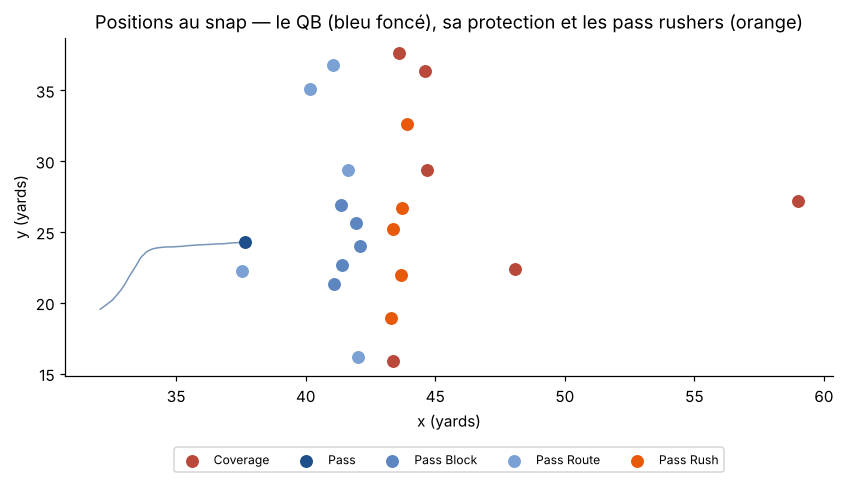

In [3]:
snap = one[one.event.isin(["ball_snap", "autoevent_ballsnap"])].frameId.min()
fig, ax = plt.subplots(figsize=(9, 4))
colors = {"Pass": "#1f4f8a", "Pass Block": "#5d86c0", "Pass Rush": ORANGE, "Coverage": "#b9493a", "Pass Route": "#7aa0d4"}
for role, g in one[one.frameId == snap].groupby("pff_role"):
    ax.scatter(g.x, g.y, s=90, c=colors.get(role, GREY), label=role, edgecolor="white")
qb = one[(one.pff_role == "Pass")]
ax.plot(qb.x, qb.y, c="#1f4f8a", lw=1, alpha=.6)
ax.set_title("Positions au snap — le QB (bleu foncé), sa protection et les pass rushers (orange)")
ax.legend(fontsize=8, ncol=5, loc="lower center", bbox_to_anchor=(.5, -.3)); ax.set_xlabel("x (yards)"); ax.set_ylabel("y (yards)")
plt.show()

## 3. Définir la métrique
Pour chaque action :
1. **Début** du chrono : l'image du snap (`ball_snap`).
2. **Fin** de la fenêtre : le lancer (`pass_forward`), le sack (`qb_sack`) ou la course du QB (`run`).
3. À chaque image, on calcule la distance entre le QB et **le pass rusher le plus proche**.
4. **Pocket Clock** = premier instant où cette distance passe sous **2 yards**. Si ça n'arrive jamais, la poche a tenu jusqu'au lancer : on note le temps du lancer et on marque l'action comme « non percée ».

Pourquoi 2 yards ? C'est environ une longueur de bras plus un pas : à cette distance, le rusher peut toucher le QB. Ce choix est testé à la section 11.

La même logique est codée dans `pocket_clock.py`, et `tests/test_pocket_clock.py` la vérifie sur des actions synthétiques dont on connaît la réponse.

Pocket Clock = 3.2 s · poche percée : False · lancer à 3.2 s


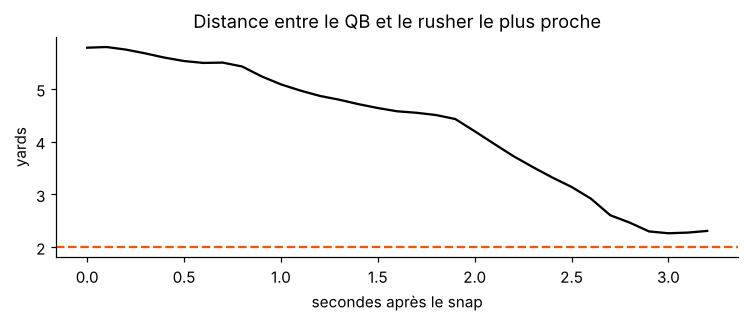

In [4]:
SNAP = {"ball_snap", "autoevent_ballsnap"}
END = {"pass_forward", "autoevent_passforward", "qb_sack", "qb_strip_sack", "run", "fumble"}
RADIUS, FPS = 2.0, 10

def pocket_clock(p):
    """p = tracking d'une action (avec pff_role). Renvoie le chrono et le détail par rusher."""
    ev = p[p.event.notna()][["frameId", "event"]].drop_duplicates()
    snap = ev[ev.event.isin(SNAP)].frameId.min()
    if pd.isna(snap):
        return None
    end_ev = ev[ev.event.isin(END) & (ev.frameId > snap)]
    end = end_ev.frameId.min() if len(end_ev) else p.frameId.max()
    win = p[(p.frameId >= snap) & (p.frameId <= end)]
    qb = win[win.pff_role == "Pass"].drop_duplicates("frameId").set_index("frameId")[["x", "y"]]
    rush = win[win.pff_role == "Pass Rush"].join(qb, on="frameId", rsuffix="_qb").dropna(subset=["x_qb"])
    if qb.empty or rush.empty:
        return None
    rush = rush.assign(d=np.hypot(rush.x - rush.x_qb, rush.y - rush.y_qb))
    closest = rush.groupby("frameId").d.min()
    hit = closest[closest < RADIUS]
    breached = len(hit) > 0
    per_rusher = rush[rush.d < RADIUS].groupby("nflId").frameId.min().sub(snap).div(FPS)
    return {"pocket_time": ((hit.index.min() if breached else end) - snap) / FPS,
            "breached": breached, "release_time": (end - snap) / FPS,
            "first_rusher": rush[rush.frameId == hit.index.min()].sort_values("d").nflId.iloc[0] if breached else np.nan,
            "n_rush": rush.nflId.nunique(), "curve": closest.values,
            "rushers": {int(n): per_rusher.get(n, np.nan) for n in rush.nflId.unique()}}

r = pocket_clock(one)
print(f"Pocket Clock = {r['pocket_time']} s · poche percée : {r['breached']} · lancer à {r['release_time']} s")
plt.figure(figsize=(8, 2.6)); plt.plot(np.arange(len(r["curve"])) / FPS, r["curve"], c="black")
plt.axhline(RADIUS, ls="--", c=ORANGE); plt.ylabel("yards"); plt.xlabel("secondes après le snap")
plt.title("Distance entre le QB et le rusher le plus proche"); plt.show()

## 4. Calculer sur les 122 matchs
Environ 2 minutes : on lit chaque fichier de tracking une fois.

In [5]:
rows, rush_rows = [], []
for f in sorted(glob.glob(f"{DATA}/tracking/tracking_*.csv")):
    t = pd.read_csv(f).merge(roles, on=["gameId", "playId", "nflId"], how="left")
    for (g, p), d in t.groupby(["gameId", "playId"]):
        r = pocket_clock(d)
        if r is None:
            continue
        for n, a in r.pop("rushers").items():
            rush_rows.append({"gameId": g, "playId": p, "nflId": n, "arrive": a})
        r.pop("curve")
        rows.append({"gameId": g, "playId": p, **r})

P = pd.DataFrame(rows).merge(plays, on=["gameId", "playId"])
R = pd.DataFrame(rush_rows)
print(f"{len(P)} actions chronométrées · {P.breached.mean():.0%} de poches percées avant le lancer")

8532 actions chronométrées · 32% de poches percées avant le lancer


## 5. Est-ce que la métrique a du sens ?
Premier test : une poche percée doit mener à de moins bons résultats. C'est le cas, et de loin.

In [6]:
res = pd.crosstab(P.breached.map({False: "Poche intacte", True: "Poche percée"}), P.passResult, normalize="index").mul(100).round(1)
res.rename(columns={"C": "Complète %", "I": "Incomplète %", "S": "Sack %", "R": "Scramble %", "IN": "Interception %"})

passResult,Complète %,Incomplète %,Interception %,Scramble %,Sack %
breached,,,,,
Poche intacte,62.9,31.2,2.1,3.5,0.3
Poche percée,35.0,34.4,2.4,8.9,19.3


## 6. Courbe de survie de la poche
Problème : quand le QB lance avant toute pression, on ne sait pas combien de temps la poche **aurait** tenu. Prendre la moyenne brute sous-estimerait la protection.

Solution classique en statistique médicale : l'estimateur de **Kaplan-Meier**. Une passe lâchée avant la pression « sort » de l'échantillon sans compter comme une poche percée. On obtient la part des poches encore intactes à chaque instant.

Tenue médiane : 3.7 s · intactes à 2,5 s : 85.2 %


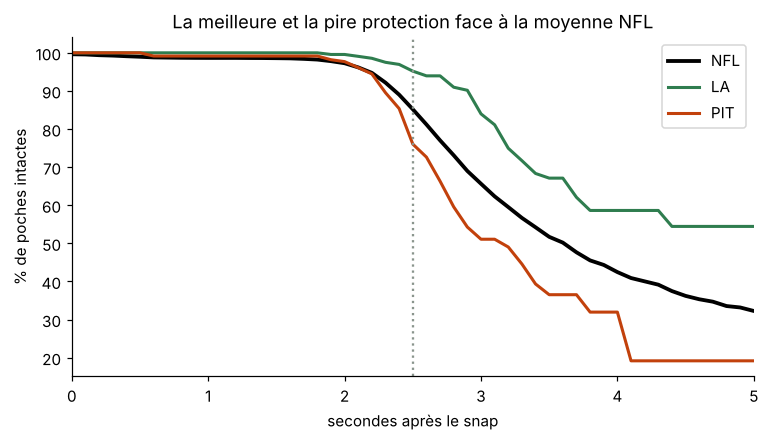

In [7]:
def survival(df, grid=np.round(np.arange(0, 6.01, .1), 1)):
    d, e = df.pocket_time.values, df.breached.values
    s, out = 1.0, []
    for t in grid:
        at_risk = (d >= t - 1e-9).sum()
        ev = ((np.abs(d - t) < .05) & e).sum()
        s *= 1 - ev / at_risk if at_risk else 1
        out.append(s * 100)
    return pd.Series(out, index=grid)

S = survival(P)
print(f"Tenue médiane : {S[S <= 50].index.min()} s · intactes à 2,5 s : {S[2.5]:.1f} %")
team = P.groupby("possessionTeam").apply(lambda g: survival(g)[2.5]).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(S.index, S.values, c="black", lw=2.5, label="NFL")
for tm, c in [(team.index[-1], GREEN), (team.index[0], RED)]:
    s = survival(P[P.possessionTeam == tm]); ax.plot(s.index, s.values, c=c, lw=2, label=tm)
ax.axvline(2.5, c=GREY, ls=":"); ax.set_xlim(0, 5); ax.set_ylabel("% de poches intactes"); ax.set_xlabel("secondes après le snap")
ax.set_title("La meilleure et la pire protection face à la moyenne NFL"); ax.legend(); plt.show()

## 7. Ce que vaut une demi-seconde
On regroupe les poches percées selon le moment où elles cèdent.

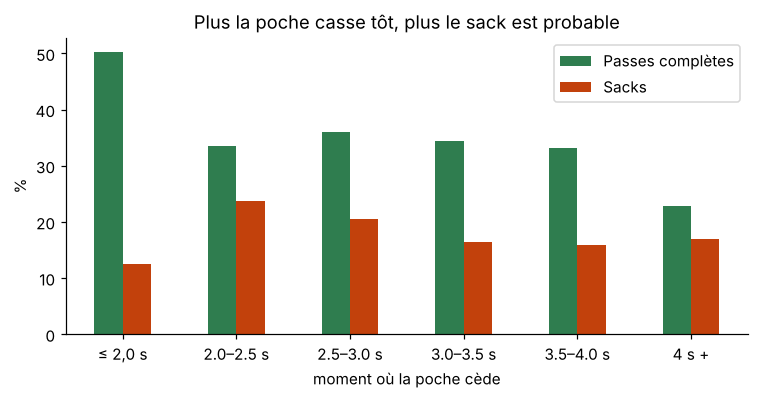

,sack,comp,n
tranche,,,
1.5,12.6,50.3,183
2.0,23.7,33.6,596
2.5,20.4,36.1,1037
3.0,16.3,34.4,514
3.5,15.9,33.2,214
4.0,17.0,22.9,188


In [8]:
B = P[P.breached].assign(tranche=lambda d: (np.floor(d.pocket_time * 2) / 2).clip(1.5, 4))
v = B.groupby("tranche").agg(sack=("passResult", lambda s: (s == "S").mean() * 100), comp=("passResult", lambda s: (s == "C").mean() * 100), n=("playId", "size"))
ax = v[["comp", "sack"]].plot.bar(color=[GREEN, RED], figsize=(8, 3.5), rot=0)
ax.set_xticklabels(["≤ 2,0 s" if x == 1.5 else ("4 s +" if x == 4 else f"{x:.1f}–{x+.5:.1f} s") for x in v.index])
ax.set_ylabel("%"); ax.set_xlabel("moment où la poche cède"); ax.legend(["Passes complètes", "Sacks"]); ax.set_title("Plus la poche casse tôt, plus le sack est probable"); plt.show()
v.round(1)

## 8. Le contexte tactique
Questions de coach : est-ce que le play action fait gagner du temps ? Combien coûte un rusher de plus ?

In [9]:
def tenue(g):
    s = survival(g)
    return pd.Series({"actions": len(g), "intactes à 2,5 s (%)": round(s[2.5], 1), "tenue médiane (s)": s[s <= 50].index.min()})

pa = P.groupby(P.pff_playAction.map({0: "Sans play action", 1: "Avec play action"})).apply(tenue)
nr = P.groupby(P.n_rush.clip(3, 6).map({3: "3 rushers", 4: "4 rushers", 5: "5 rushers", 6: "6+ (blitz)"})).apply(tenue)
pd.concat([pa, nr])

,actions,"intactes à 2,5 s (%)",tenue médiane (s)
Avec play action,2035.0,89.5,4.6
Sans play action,6497.0,83.1,3.3
3 rushers,438.0,93.3,NaN
4 rushers,5990.0,86.9,3.7
5 rushers,1686.0,79.7,3.2
6+ (blitz),418.0,71.3,3.0


## 9. Classements individuels
**Pass rushers — « premier arrivé »** : part des snaps où le joueur est le premier à percer la zone de 2 yards. Mesure qui crée la pression lui-même, et pas celui qui profite du travail d'un coéquipier.

**Ligne offensive — « bloc tenu »** : PFF indique quel défenseur chaque protecteur bloque. On regarde si ce défenseur atteint le QB.

In [10]:
first = P.first_rusher.dropna().astype(int).value_counts()
rk = R.groupby("nflId").agg(snaps=("playId", "size"), arrive=("arrive", lambda a: a.notna().mean() * 100))
rk["premier_arrivé_%"] = (first.reindex(rk.index).fillna(0) / rk.snaps * 100).round(1)
rk = rk[rk.snaps >= 120].join(players.set_index("nflId")[["displayName", "officialPosition"]])
rk.sort_values("premier_arrivé_%", ascending=False).head(10)[["displayName", "officialPosition", "snaps", "premier_arrivé_%"]]

,displayName,officialPosition,snaps,premier_arrivé_%
nflId,,,,
44915,Trey Hendrickson,DE,216,20.4
44813,Myles Garrett,DE,208,19.7
43358,Yannick Ngakoue,DE,198,19.2
43435,Matt Judon,OLB,189,17.5
44838,Takkarist McKinley,DE,120,16.7
37075,Von Miller,OLB,159,14.5
42403,Randy Gregory,DE,146,14.4
43378,Javon Hargrave,DT,169,14.2
47799,Brian Burns,DE,201,13.9


In [11]:
blk = pff[pff.pff_role == "Pass Block"].merge(
    R.rename(columns={"nflId": "pff_nflIdBlockedPlayer", "arrive": "adv_arrive"}), on=["gameId", "playId", "pff_nflIdBlockedPlayer"])
ol = blk.groupby("nflId").agg(snaps=("playId", "size"), bloc_tenu=("adv_arrive", lambda a: a.isna().mean() * 100),
                              sacks_concédés=("pff_sackAllowed", "sum"))
ol = ol[ol.snaps >= 100].join(players.set_index("nflId")[["displayName", "officialPosition"]])
ol.sort_values("bloc_tenu", ascending=False).head(10).round(1)

,snaps,bloc_tenu,sacks_concédés,displayName,officialPosition
nflId,,,,,
44068,131,96.9,0.0,Lucas Patrick,G
37130,139,96.4,0.0,Rodney Hudson,C
40151,292,96.2,1.0,Ryan Jensen,C
46180,233,95.7,3.0,Brian Allen,C
42392,243,95.5,1.0,Mitch Morse,C
42348,110,95.5,0.0,Brandon Scherff,G
41322,154,95.5,1.0,Brandon Linder,G
53491,107,95.3,0.0,Josh Myers,C
52421,295,95.3,1.0,Tristan Wirfs,T


## 10. Fatigue : une fausse bonne idée ?
Hypothèse : un rusher fatigué arrive moins souvent sur le QB en fin de match.

Résultat : **le taux monte au lieu de baisser.** Ce n'est pas que la fatigue n'existe pas : les joueurs qui cumulent beaucoup de snaps sont les titulaires d'élite, et les fins de match amènent des situations de passe évidentes. Un résultat honnête vaut mieux qu'une jolie courbe qui raconte la mauvaise histoire. Pour isoler la fatigue, il faudrait comparer chaque joueur à lui-même, à situation de jeu égale.

In [12]:
Rf = R.merge(P[["gameId", "playId", "quarter"]], on=["gameId", "playId"]).sort_values(["gameId", "nflId", "playId"])
Rf["snap_n"] = Rf.groupby(["gameId", "nflId"]).cumcount() + 1
Rf["tranche"] = pd.cut(Rf.snap_n, [0, 10, 20, 30, 40, 99], labels=["1–10", "11–20", "21–30", "31–40", "41+"])
Rf.groupby("tranche", observed=True).arrive.apply(lambda a: round(a.notna().mean() * 100, 1)).rename("% de snaps où le rusher atteint le QB")

tranche
1–10     10.5
11–20    10.9
21–30    13.5
31–40    14.2
41+      23.3
Name: % de snaps où le rusher atteint le QB, dtype: float64

## 11. Est-ce que c'est solide ?
Trois vérifications, calculées par `validate.py` :

1. **Le seuil de 2 yards** : on recalcule tout avec 1,5, 2,5 et 3 yards et on compare les classements.
2. **Le modèle de recommandation** : entraîné sur les semaines 1 à 6, testé sur les semaines 7 et 8 qu'il n'a jamais vues.
3. **La calibration** : quand le modèle annonce 30 % de poches percées, en observe-t-on bien 30 % ?

In [13]:
import json, subprocess, sys
subprocess.run([sys.executable, "pocket_clock.py", DATA], check=True, capture_output=True)
subprocess.run([sys.executable, "validate.py"], check=True, capture_output=True)
V = json.load(open("validation.json"))
pd.DataFrame(V["sensitivity"]).rename(columns={"radius": "rayon (yd)", "breach": "poches percées %", "team_spearman": "corrélation classement équipes",
                                               "rusher_spearman": "corrélation classement rushers", "rusher_top10_overlap": "top 10 rushers identique"})

,rayon (yd),poches percées %,corrélation classement équipes,corrélation classement rushers,top 10 rushers identique
0,1.5,18.6,0.806,0.895,6
1,2.0,31.9,1.000,1.000,10
2,2.5,53.2,0.688,0.748,6
3,3.0,70.1,0.629,0.536,2


**Lecture.** Entre 1,5 et 2 yards, les classements restent proches, avec une corrélation de 0,8 à 0,9. À 2,5 et 3 yards, plus de la moitié des poches comptent comme « percées » alors que le rusher est seulement au contact d'un bloqueur : la mesure perd son pouvoir de distinction. **2 yards est le seuil le plus large qui garde un vrai signal.**

Semaines 7-8 : 1945 actions jamais vues
Score de Brier : 0.2188 (moyenne ligue) -> 0.2134 (modèle), soit -2.5 %
AUC : 0.597


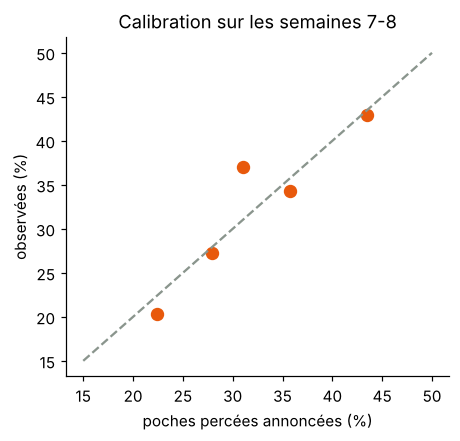

In [14]:
h = V["holdout"]
print(f"Semaines 7-8 : {h['test_plays']} actions jamais vues")
print(f"Score de Brier : {h['brier_base']} (moyenne ligue) -> {h['brier_model']} (modèle), soit -{h['gain_brier_pct']} %")
print(f"AUC : {h['auc']}")
cal = pd.DataFrame(V["calibration"])
plt.figure(figsize=(4.5, 4)); plt.plot([15, 50], [15, 50], c=GREY, ls="--")
plt.scatter(cal.pred, cal.obs, s=60, c=ORANGE); plt.xlabel("poches percées annoncées (%)"); plt.ylabel("observées (%)")
plt.title("Calibration sur les semaines 7-8"); plt.show()

**Lecture.** Le modèle est bien calibré : les points suivent la diagonale. Il bat la moyenne de la ligue, mais modestement, avec une AUC de 0,60 : une action isolée reste très incertaine. Il sert donc à **comparer des options** sur de nombreux snaps, pas à prédire un snap précis. C'est exactement l'usage d'un plan de match.

## 12. Le plan de match : une recommandation testable
Le modèle `model.py` combine :
- la probabilité que la poche soit percée, selon l'attaque, la défense, le nombre de rushers, le play action et la situation ;
- les conséquences observées, yards et sacks, quand la poche tient ou casse, dans la même situation.

Exemple : Kansas City défend contre Buffalo en 3e & long. Combien de rushers envoyer ?

In [15]:
from model import fit_model, outcomes, expected, RUSH_LABEL
Pm = pd.read_csv("plays_pocket_clock.csv")
mdl, outc = fit_model(Pm, k=100), outcomes(Pm)
pa_buf = Pm[Pm.possessionTeam == "BUF"].pff_playAction.mean()
rows = []
for r in (3, 4, 5, 6):
    e0, e1 = expected(mdl, outc, "BUF", "KC", r, 0, down=3, togo=10), expected(mdl, outc, "BUF", "KC", r, 1, down=3, togo=10)
    mix = {k: e0[k] * (1 - pa_buf) + e1[k] * pa_buf for k in e0}
    rows.append({"option": RUSH_LABEL[r], "poche percée %": round(mix["p_breach"] * 100, 1),
                 "sacks %": round(mix["sack"] * 100, 1), "yards concédés": round(mix["yards"], 2)})
pd.DataFrame(rows).sort_values("yards concédés")

,option,poche percée %,sacks %,yards concédés
3,6+ (blitz),43.8,10.3,5.97
2,5 rushers,46.3,13.6,6.56
1,4 rushers,41.9,8.6,6.81
0,3 rushers,29.0,5.8,7.16


Le tableau de bord fait exactement ce calcul en direct, pour n'importe quel duel et n'importe quelle situation.

## 13. Limites et prochaines étapes
- **Rayon fixe de 2 yards** : un rusher bloqué au contact peut être à 2 yards sans menacer réellement. Prochaine étape : tenir compte de la vitesse et de l'orientation du rusher vers le QB.
- **QB mobiles** : un QB qui sort de la poche « allonge » artificiellement le chrono.
- **Échantillon** : 8 semaines seulement. Les classements individuels sont indicatifs.
- **Recommandation** : les issues observées mélangent des contextes variés, et aucun essai contrôlé n'existe en NFL. Les cases peu observées sont signalées dans le tableau de bord et ramenées vers la moyenne.

**Qui l'utiliserait ?** Le coach de ligne offensive, pour voir où et quand sa protection lâche. Le recruteur, pour repérer les rushers qui créent la pression eux-mêmes. Le commentateur, pour afficher un chrono de poche en direct.

## 14. Générer le tableau de bord
```bash
python pocket_clock.py data    # calcule les CSV
python validate.py             # validation et robustesse
python export.py data          # construit dashboard_data.json + les rejeux
python build_dashboard.py      # assemble index.html
python -m pytest tests         # 15 tests automatiques
```
Le JSON est ensuite intégré dans `pocket_clock_dashboard.html`, qui s'ouvre dans n'importe quel navigateur.